# EDA - Student Study Habits

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/MSDS 621; Project/"
except ImportError:
    DATA_DIR = "./"   # CSVs in the same folder as this notebook

FIG_DIR = DATA_DIR + "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load and row counts (evidence for the report)

In [ ]:
raw = pd.read_csv(DATA_DIR + "Student_Study_Habit.csv")
cl = pd.read_csv(DATA_DIR + "student_study_habits_cleaned.csv")


raw812 = raw[raw["Year"] != "Other"].reset_index(drop=True)

counts = pd.DataFrame({
    "stage": ["Raw file", "Rows with Year = Other (dropped)", "Raw without Year = Other", "Cleaned file"],
    "rows": [len(raw), (raw["Year"] == "Other").sum(), len(raw812), len(cl)],
    "columns": [raw.shape[1], "", raw812.shape[1], cl.shape[1]],
})
print(counts.to_string(index=False))
print("\nMissing values  raw:", raw.isna().sum().sum(), " cleaned:", cl.isna().sum().sum())
print("Duplicate rows  raw:", raw.duplicated().sum(), " cleaned:", cl.duplicated().sum())


                           stage  rows columns
                        Raw file  1000      16
Rows with Year = Other (dropped)   188        
        Raw without Year = Other   812      16
                    Cleaned file   812      28

Missing values  raw: 0  cleaned: 0
Duplicate rows  raw: 0  cleaned: 0


## 2. Category counts (full raw file)

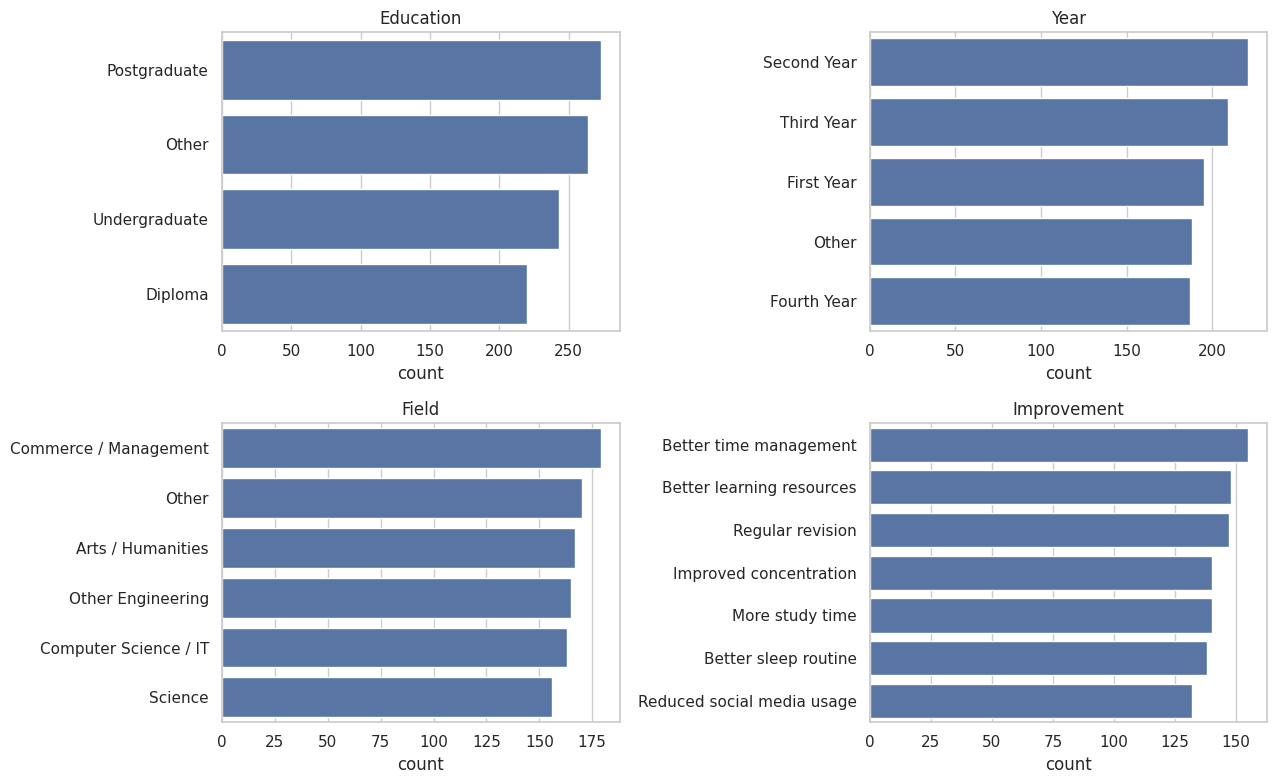

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["Education", "Year", "Field", "Improvement"]):
    order = raw[col].value_counts().index
    sns.countplot(data=raw, y=col, order=order, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_ylabel("")
save("01_category_counts")


## 3. Target distribution (exam percentage)

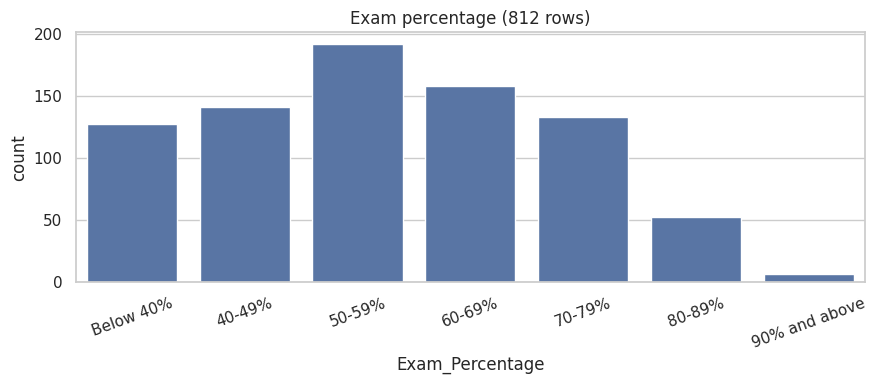

In [ ]:
orders = {
    "Study_Hours": ["Less than 1 hour", "1-2 hours", "2-3 hours", "3-5 hours", "More than 5 hours"],
    "Sleep_Hours": ["Less than 5 hours", "5-6 hours", "6-7 hours", "7-8 hours", "More than 8 hours"],
    "Attendance": ["Below 50%", "50-65%", "66-75%", "76-90%", "Above 90%"],
    "Revision": ["Rarely", "Only before exams", "Once a week", "Several times a week", "Daily"],
    "Social_Media": ["Less than 1 hour", "1-2 hours", "2-4 hours", "4-6 hours", "More than 6 hours"],
    "Exam_Percentage": ["Below 40%", "40-49%", "50-59%", "60-69%", "70-79%", "80-89%", "90% and above"],
}
exam_map = {v: i for i, v in enumerate(orders["Exam_Percentage"])}
raw812["Exam_Score"] = raw812["Exam_Percentage"].map(exam_map)   # 0 = Below 40%, 6 = 90% and above
raw812["Study_Score"] = raw812["Study_Hours"].map({v: i for i, v in enumerate(orders["Study_Hours"])})  # 0-4

plt.figure(figsize=(9, 4))
sns.countplot(data=raw812, x="Exam_Percentage", order=orders["Exam_Percentage"], color="#4C72B0")
plt.title("Exam percentage (812 rows)")
plt.xticks(rotation=20)
save("02_exam_distribution")


## 4. Mean and variance (cleaned numeric data)

In [ ]:
num_cols = ["year", "study_hours", "sleep_hours", "attendance", "revision", "exam_prep",
            "social_media", "distraction", "concentration", "assignment_completion",
            "confidence", "exam_percentage"]

summary = cl[num_cols].agg(["mean", "var", "std", "min", "max"]).T.round(2)
print(summary)
summary.to_csv(f"{FIG_DIR}/mean_variance_table.csv")


                       mean   var   std  min  max
year                   1.48  1.19  1.09  0.0  3.0
study_hours            1.99  2.03  1.42  0.0  4.0
sleep_hours            2.11  1.91  1.38  0.0  4.0
attendance             1.97  1.98  1.41  0.0  4.0
revision               2.00  1.96  1.40  0.0  4.0
exam_prep              2.05  1.89  1.38  0.0  4.0
social_media           2.00  1.94  1.39  0.0  4.0
distraction            1.92  1.98  1.41  0.0  4.0
concentration          3.03  2.02  1.42  1.0  5.0
assignment_completion  1.97  2.05  1.43  0.0  4.0
confidence             3.03  2.03  1.42  1.0  5.0
exam_percentage        2.26  2.31  1.52  0.0  6.0


## 5. Correlation matrix

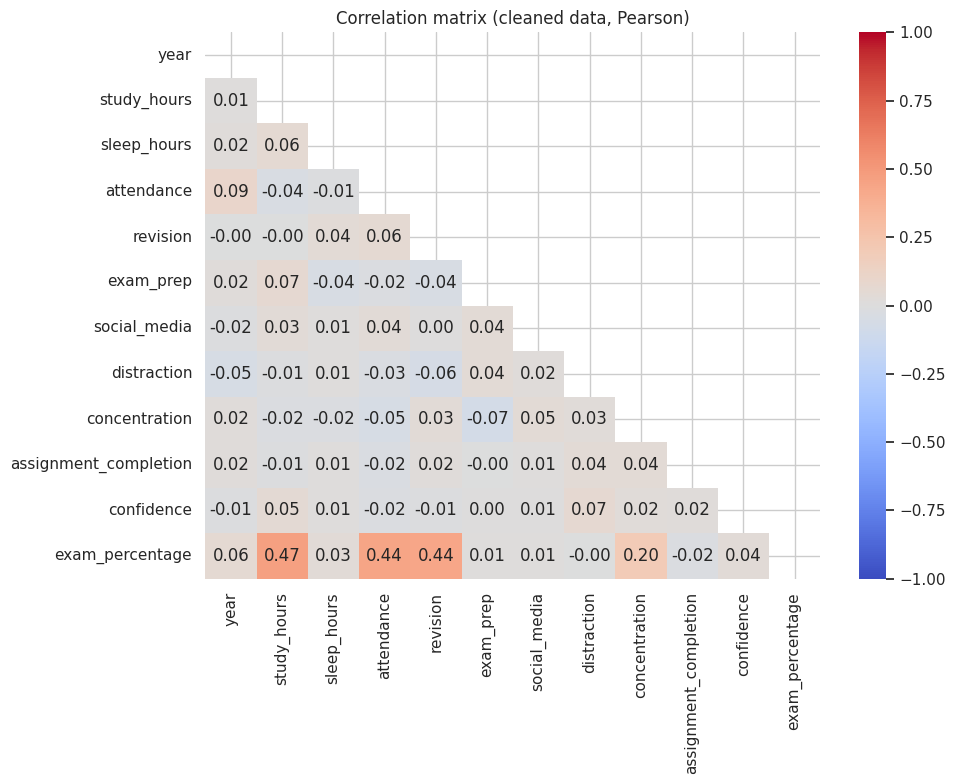

Correlation with exam_percentage
study_hours              0.468
attendance               0.438
revision                 0.436
concentration            0.202
year                     0.061
confidence               0.036
sleep_hours              0.034
social_media             0.014
exam_prep                0.008
distraction             -0.001
assignment_completion   -0.021
Name: exam_percentage, dtype: float64

Spearman with exam_percentage
study_hours              0.467
attendance               0.441
revision                 0.432
concentration            0.196
year                     0.061
confidence               0.044
sleep_hours              0.033
social_media             0.013
exam_prep                0.005
distraction             -0.007
assignment_completion   -0.024
Name: exam_percentage, dtype: float64


In [ ]:
corr = cl[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (cleaned data, Pearson)")
save("03_correlation_matrix")

print("Correlation with exam_percentage")
print(corr["exam_percentage"].drop("exam_percentage").sort_values(ascending=False).round(3))

# The columns are ordinal, so check Spearman as well
spear = cl[num_cols].corr(method="spearman")["exam_percentage"].drop("exam_percentage")
print("\nSpearman with exam_percentage")
print(spear.sort_values(ascending=False).round(3))


## 6. Boxplots: exam score by habit

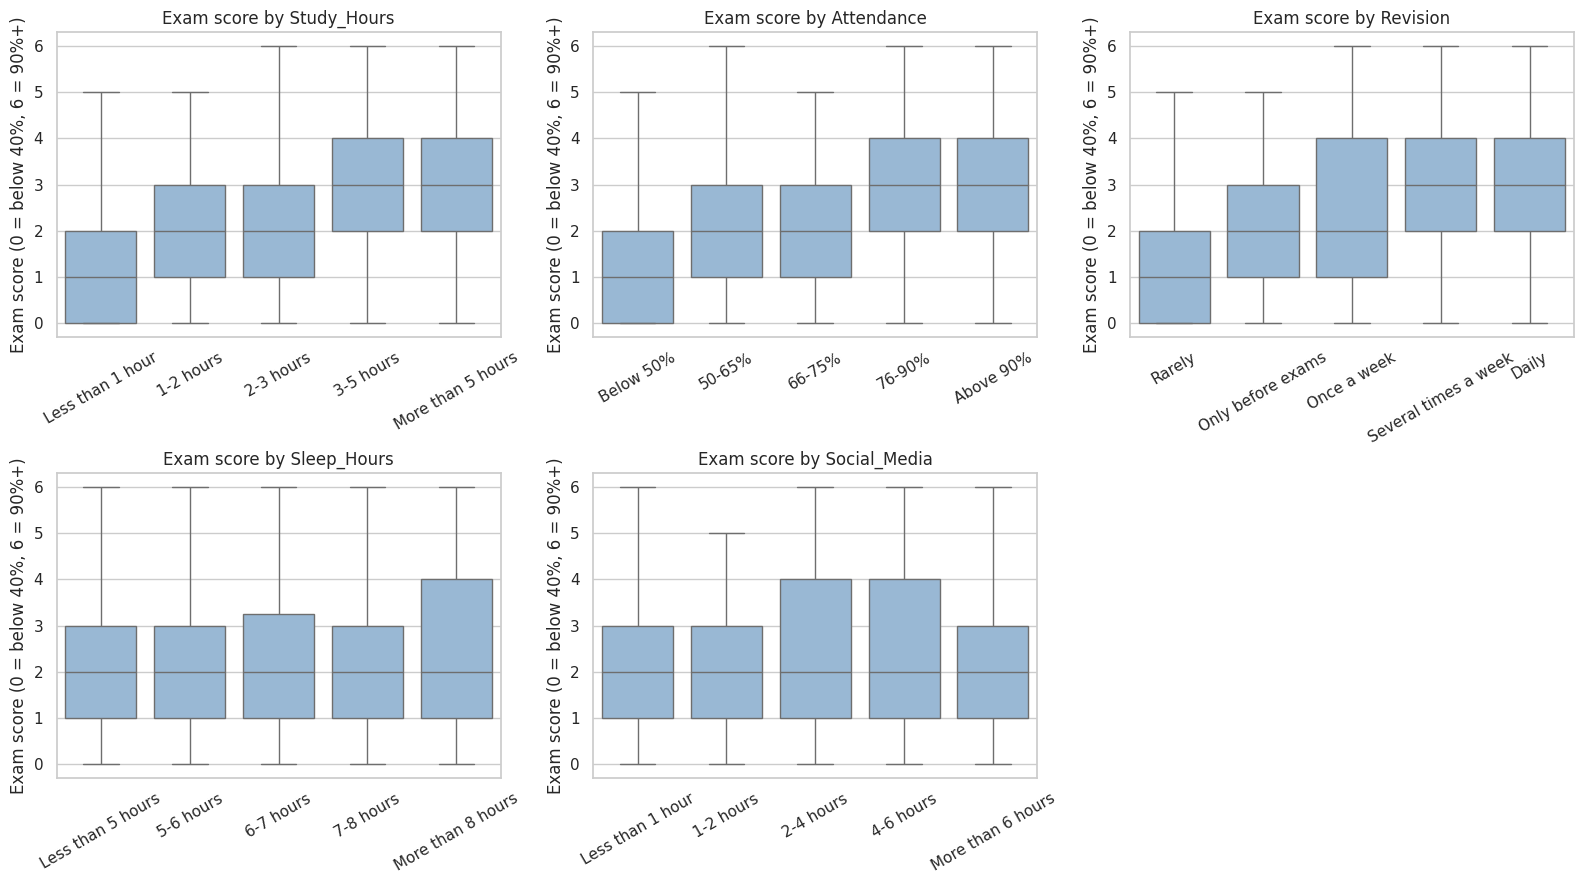

In [ ]:
habits = ["Study_Hours", "Attendance", "Revision", "Sleep_Hours", "Social_Media"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, h in zip(axes.ravel(), habits):
    sns.boxplot(data=raw812, x=h, y="Exam_Score", order=orders[h], ax=ax, color="#8FB8DE")
    ax.set_title(f"Exam score by {h}")
    ax.set_ylabel("Exam score (0 = below 40%, 6 = 90%+)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
save("04_boxplots_exam_by_habit")


## 7. Mean exam score by habit level (bar plots)

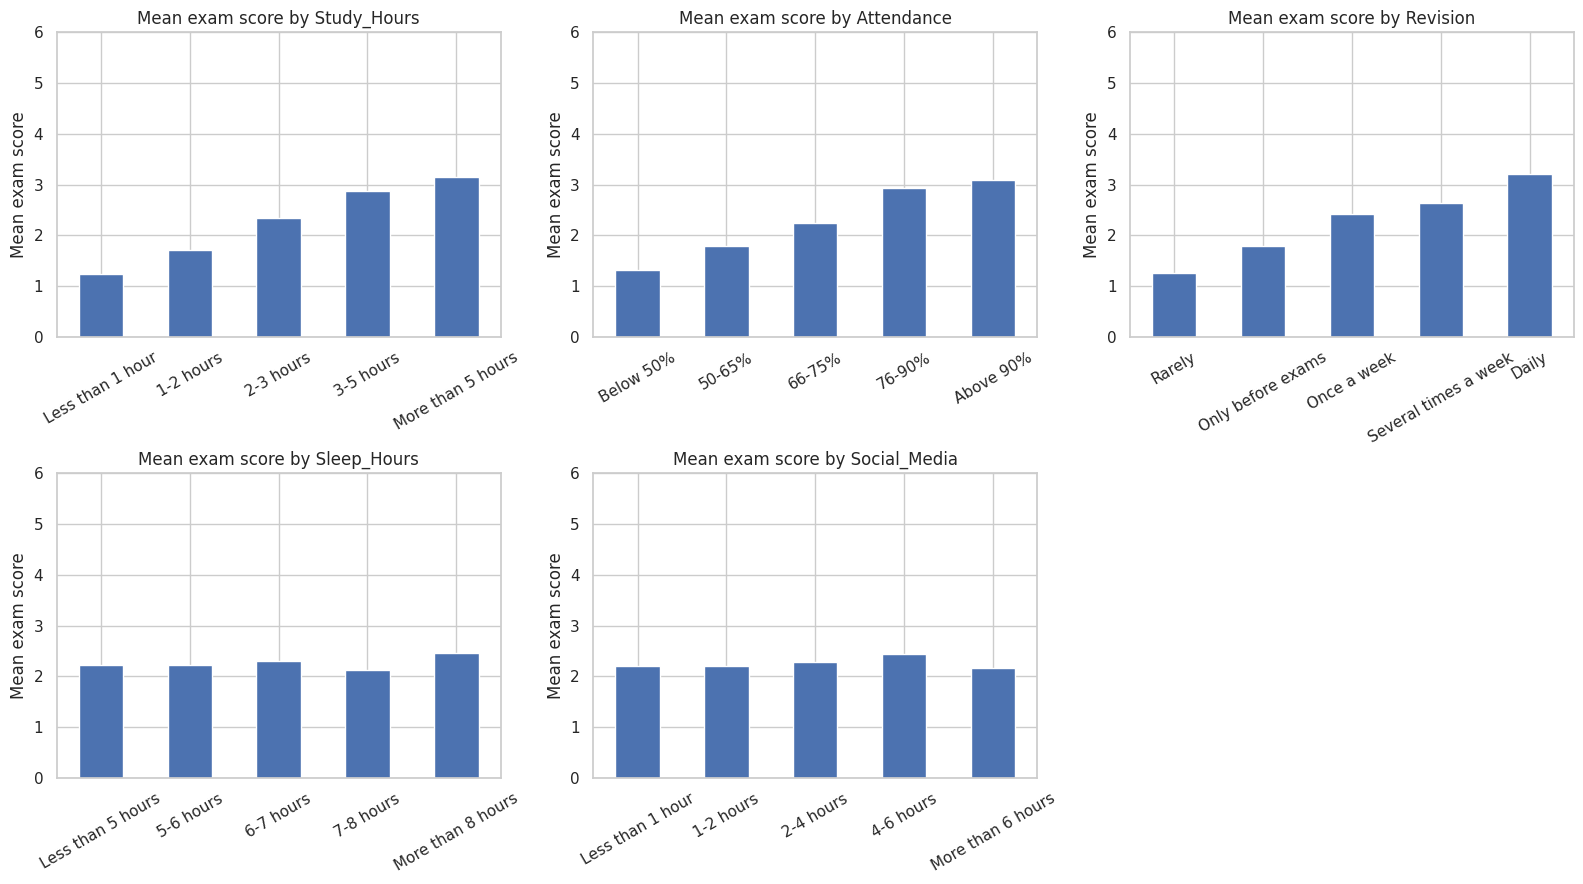

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, h in zip(axes.ravel(), habits):
    means = raw812.groupby(h)["Exam_Score"].mean().reindex(orders[h])
    means.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(f"Mean exam score by {h}")
    ax.set_xlabel("")
    ax.set_ylabel("Mean exam score")
    ax.set_ylim(0, 6)
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
save("05_mean_exam_by_habit")


## 8. Scatter plot (with jitter, since values are discrete)

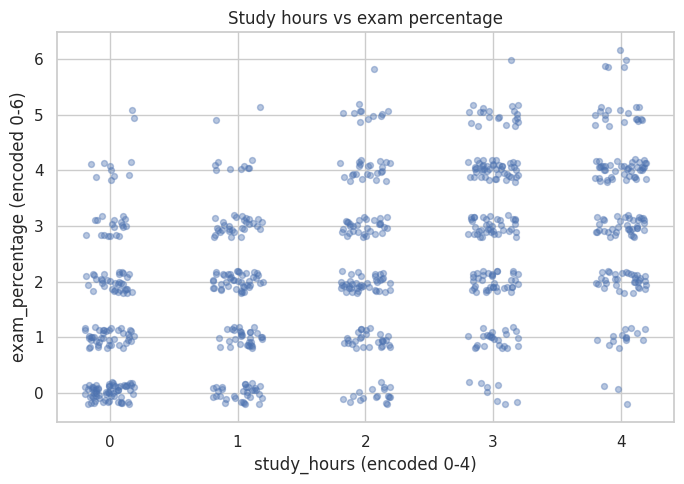

In [ ]:
rng = np.random.default_rng(0)
x = cl["study_hours"] + rng.uniform(-0.2, 0.2, len(cl))
y = cl["exam_percentage"] + rng.uniform(-0.2, 0.2, len(cl))
plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.4, s=18)
plt.xlabel("study_hours (encoded 0-4)")
plt.ylabel("exam_percentage (encoded 0-6)")
plt.title("Study hours vs exam percentage")
save("06_scatter_study_vs_exam")


## 9. Field of study comparison

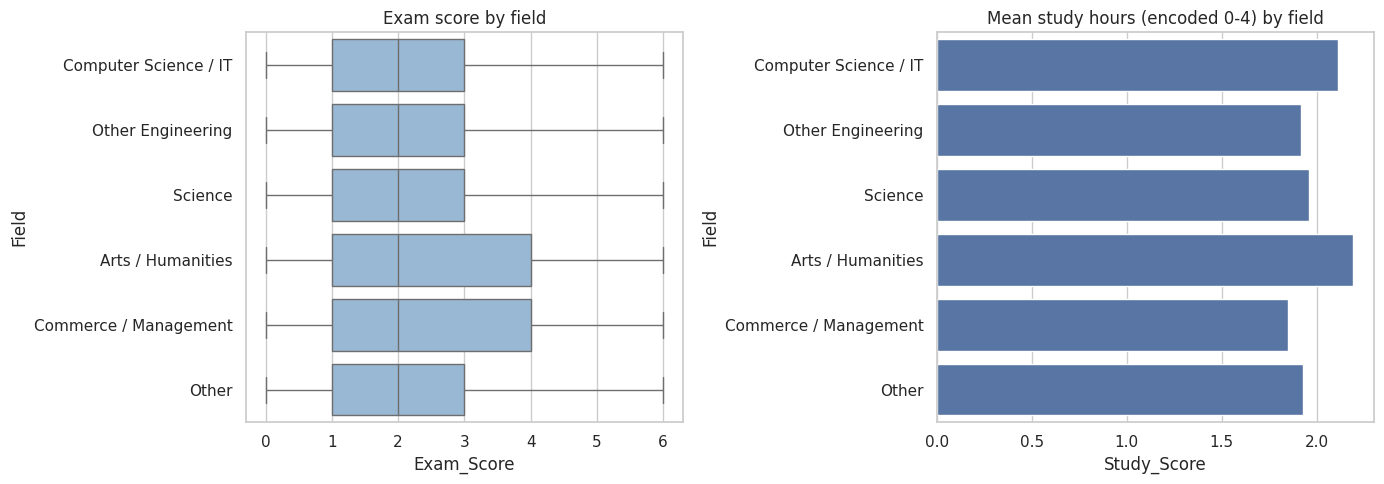

Kruskal-Wallis, exam score across fields: KruskalResult(statistic=np.float64(1.9135174752127846), pvalue=np.float64(0.8609774929149591))


In [ ]:
field_order = raw812.groupby("Field")["Exam_Score"].mean().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=raw812, y="Field", x="Exam_Score", order=field_order, ax=axes[0], color="#8FB8DE")
axes[0].set_title("Exam score by field")
sns.barplot(data=raw812, y="Field", x="Study_Score", order=field_order, ax=axes[1], color="#4C72B0", errorbar=None)
axes[1].set_title("Mean study hours (encoded 0-4) by field")
save("07_field_comparison")

groups = [g["Exam_Score"].values for _, g in raw812.groupby("Field")]
print("Kruskal-Wallis, exam score across fields:", stats.kruskal(*groups))


## 10. 'Improvement' column (K-means comparison)

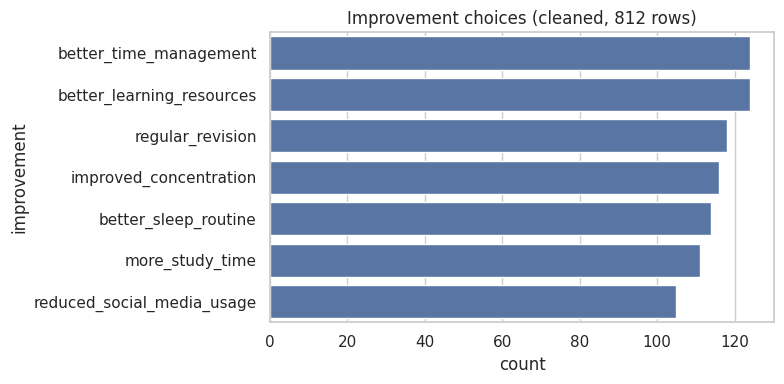

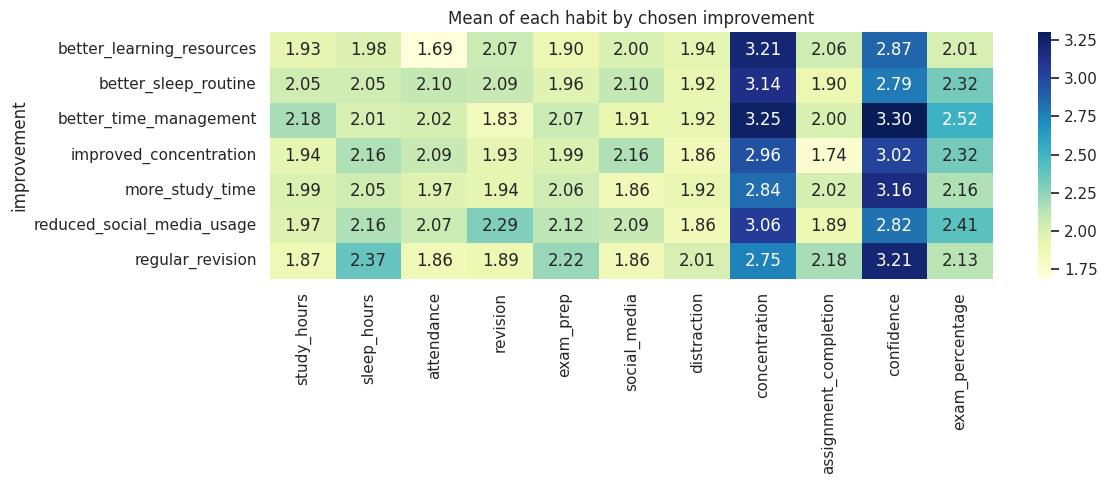

                            study_hours  sleep_hours  attendance  revision  \
improvement                                                                  
better_learning_resources          1.93         1.98        1.69      2.07   
better_sleep_routine               2.05         2.05        2.10      2.09   
better_time_management             2.18         2.01        2.02      1.83   
improved_concentration             1.94         2.16        2.09      1.93   
more_study_time                    1.99         2.05        1.97      1.94   
reduced_social_media_usage         1.97         2.16        2.07      2.29   
regular_revision                   1.87         2.37        1.86      1.89   

                            exam_prep  social_media  distraction  \
improvement                                                        
better_learning_resources        1.90          2.00         1.94   
better_sleep_routine             1.96          2.10         1.92   
better_time_management   

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=cl, y="improvement", order=cl["improvement"].value_counts().index, color="#4C72B0")
plt.title("Improvement choices (cleaned, 812 rows)")
save("08_improvement_counts")

habit_cols = ["study_hours", "sleep_hours", "attendance", "revision", "exam_prep", "social_media",
              "distraction", "concentration", "assignment_completion", "confidence", "exam_percentage"]
by_imp = cl.groupby("improvement")[habit_cols].mean().round(2)
plt.figure(figsize=(12, 5))
sns.heatmap(by_imp, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Mean of each habit by chosen improvement")
save("09_habits_by_improvement")
print(by_imp)
